# Building Defect AI Notebook workflow

Run from the repository root. Expected data layout: `dataset/BD3_split/{train,val,test}/<class_name>/...`.

**Task:** classify images into the seven BD3 labels. This notebook records the method, why it is used, the result and its interpretation. Do not treat model predictions as professional inspection findings.

In [1]:
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader

from PIL import Image

# Automatically detect project root
CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name == "notebooks":
    ROOT = CURRENT_DIR.parent
else:
    ROOT = CURRENT_DIR

# Project paths
DATA = ROOT / "dataset" / "BD3_split"
MODEL_PATH = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Dataset:", DATA)
print("Device:", DEVICE)

assert DATA.exists(), f"Dataset not found: {DATA}"

print("Project paths verified successfully.")

Project root: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI
Dataset: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\dataset\BD3_split
Device: cuda
Project paths verified successfully.


## 1. Evaluate the selected checkpoint on the held-out test set

This is the final performance estimate. Do not use the test set to tune hyperparameters. The checkpoint is expected to contain `model_state_dict`, `num_classes`, `class_names`, as saved by the project training scripts.

In [2]:
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
CKPT = ROOT / "models" / "building_defect_resnet18_experiment3.pth"
assert CKPT.exists(), f"Copy the Experiment 3 checkpoint to {CKPT}"
checkpoint = torch.load(CKPT, map_location=DEVICE, weights_only=True)
class_names = checkpoint["class_names"]
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, checkpoint["num_classes"])
model.load_state_dict(checkpoint["model_state_dict"])
model.to(DEVICE).eval()
test_ds = datasets.ImageFolder(DATA / "test", transform=models.ResNet18_Weights.DEFAULT.transforms())
assert test_ds.classes == class_names, (test_ds.classes, class_names)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        pred = model(x.to(DEVICE)).argmax(1).cpu().tolist()
        y_pred.extend(pred); y_true.extend(y.tolist())
print("Test accuracy:", f"{accuracy_score(y_true, y_pred):.4%}")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))


Test accuracy: 87.9245%
              precision    recall  f1-score   support

       algae     0.9528    0.9758    0.9641       124
 major_crack     0.7656    0.8448    0.8033       116
 minor_crack     0.8878    0.6905    0.7768       126
     peeling     0.8868    0.9038    0.8952       104
       plain     0.9213    0.9750    0.9474       120
    spalling     0.8158    0.9300    0.8692       100
       stain     0.9368    0.8476    0.8900       105

    accuracy                         0.8792       795
   macro avg     0.8810    0.8811    0.8780       795
weighted avg     0.8824    0.8792    0.8777       795



## 2. Confusion matrix

Rows are actual classes and columns are predicted classes. Off-diagonal values show which categories are confused. Inspect crack classes carefully because missing a major crack may have higher practical consequence than confusing two visually similar surface categories.

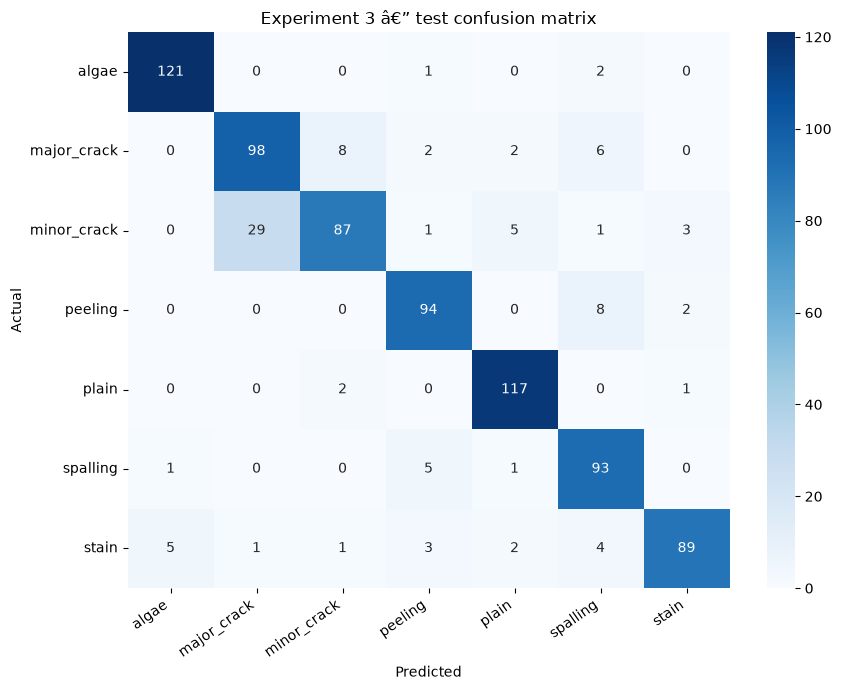

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9,7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Experiment 3 â€” test confusion matrix")
plt.xticks(rotation=35, ha="right"); plt.yticks(rotation=0); plt.tight_layout()
out = ROOT / "outputs" / "figures"; out.mkdir(parents=True, exist_ok=True)
plt.savefig(out / "experiment3_test_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


In [4]:
import json
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score

# Create report directory
REPORT_DIR = ROOT / "outputs" / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Calculate final metrics
accuracy = accuracy_score(y_true, y_pred)

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

# Save results
results = {
    "model": "ResNet18 Experiment 3",
    "architecture": "ResNet18",
    "dataset": "BD3",
    "num_classes": len(class_names),
    "test_images": len(y_true),
    "test_accuracy": accuracy,
    "class_names": class_names,
    "classification_report": report
}

report_path = REPORT_DIR / "experiment3_evaluation.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4)

print(f"Test accuracy: {accuracy:.4%}")
print(f"Test images: {len(y_true)}")
print(f"Results saved: {report_path}")

Test accuracy: 87.9245%
Test images: 795
Results saved: d:\02_LEARNING\03_Courses\04_Hope AI & Data Science Course\00_Sessions\Week11-Deep Learning Module\Building_Defect_AI\outputs\reports\experiment3_evaluation.json


## 3. Final Model Evaluation and Interpretation

### Overall performance

The Experiment 3 ResNet18 model achieved:

| Metric | Result |
|---|---:|
| Test images | 795 |
| Correct predictions | 699 |
| Incorrect predictions | 96 |
| Test accuracy | **87.92%** |
| Macro F1-score | 87.80% |
| Weighted F1-score | 87.77% |

The model correctly classified approximately 88 out of every 100 test images.

The close values of macro F1-score (87.80%) and weighted F1-score (87.77%) indicate that the overall performance is reasonably consistent across the evaluated classes, rather than being driven only by the larger classes.

### Class-wise performance

| Class | Precision | Recall | F1-score |
|---|---:|---:|---:|
| algae | 95.28% | 97.58% | 96.41% |
| major_crack | 76.56% | 84.48% | 80.33% |
| minor_crack | 88.78% | 69.05% | 77.68% |
| peeling | 88.68% | 90.38% | 89.52% |
| plain | 92.13% | 97.50% | 94.74% |
| spalling | 81.58% | 93.00% | 86.92% |
| stain | 93.68% | 84.76% | 89.00% |

### Interpretation of individual classes

**1. Algae — Strong performance**

Recall: 97.58%

The model correctly identifies nearly all algae samples. Its high precision (95.28%) also indicates that relatively few images from other categories are incorrectly labelled as algae.

This suggests that the model has learned useful visual characteristics associated with this category.

**2. Major cracks — Moderate performance**

Recall: 84.48%

The model identifies most major-crack samples, but its precision is lower at 76.56%.

This suggests that the model sometimes predicts major cracks in images belonging to other categories.

**3. Minor cracks — Main classification weakness**

Recall: 69.05%

This is the lowest recall among the seven categories.

Out of 126 actual minor-crack images, the model correctly identifies 87.

The remaining 39 images are assigned to other categories.

This is important because the model may fail to recognise some minor cracks. The distinction between major and minor cracks is particularly challenging because both categories can share similar visual textures, with differences in apparent scale and severity.

The model's high precision (88.78%) but lower recall indicates that when it predicts minor_crack, it is often correct, but it misses a notable proportion of actual minor-crack images.

**4. Peeling — Good performance**

Recall: 90.38%

The model recognises most peeling samples. Its confusion matrix also shows some predictions as spalling.

This is plausible as both categories can contain irregular surface deterioration patterns.

**5. Plain — Strong performance**

Recall: 97.50%

The model correctly identifies 117 out of 120 plain images.

This indicates that the model distinguishes most non-defect surface samples from the other categories.

**6. Spalling — Good recall, moderate precision**

Recall: 93.00%

The model identifies 93 out of 100 actual spalling images.

However, precision is 81.58%, suggesting that some images from other categories are also incorrectly classified as spalling.

**7. Stain — Good performance**

Recall: 84.76%

The model correctly identifies 89 out of 105 stain images.

Although precision is high (93.68%), some actual stain samples are classified as other categories.

### Confusion matrix interpretation

The confusion matrix provides more detail than accuracy alone.

The most important observation is the lower recall of minor_crack.

The model also shows classification errors involving visually related surface conditions. These errors suggest that learning general surface textures is easier than learning fine-grained differences between certain defect categories.

### Comparison of experiments

| Experiment | Training strategy | Test accuracy |
|---|---|---:|
| Experiment 1 | Frozen ResNet18 backbone | 83.14% |
| Experiment 2 | Fine-tune Layer3, Layer4 and classifier | 79.75% |
| Experiment 3 | Fine-tune Layer4 and classifier with early stopping | **87.92%** |

Experiment 3 improved test accuracy by:

- 4.78 percentage points compared with Experiment 1.
- 8.17 percentage points compared with Experiment 2.

Fine-tuning more layers did not automatically improve performance. Experiment 2 showed that increasing the number of trainable parameters can increase overfitting risk.

Experiment 3 provided a better balance between adapting pretrained features and retaining useful ImageNet representations.

### Final conclusion

Experiment 3 is selected as the final candidate model.

Its test accuracy of 87.92% demonstrates that ResNet18 transfer learning can distinguish the seven BD3 surface categories with reasonably strong performance.

However, the model is not equally reliable across all classes. Minor-crack detection remains the main weakness and should be prioritised in future improvements.

The results demonstrate image-classification capability, not professional defect diagnosis or structural assessment.